# Digital Preservation of Cultural Artifacts — Part 1: NeRF (Nerfacto) Training and Evaluation

**Artifact:** `binh_gom_1` (`ceramic_vases_1`) — LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts dataset.

## Objectives (this notebook)
1. Reconstruct the ceramic artifact with **Nerfacto** (NeRF, Nerfstudio 1.1.5) — 5,000 iterations at 512 x 512.
2. Evaluate the reconstruction on the 18 held-out views with PSNR, SSIM and LPIPS.
3. Back up the verified checkpoint, evaluation JSON, config and renders.

The companion notebook `Splatfacto_Cultural_Artifact_Final.ipynb` trains and evaluates the 3D Gaussian Splatting model (Splatfacto) and contains the two-model comparison, the reference-mesh validation and the interactive 3D viewer.

---
### How to run (Kaggle)

1. **Settings -> Accelerator -> GPU T4 x2** (training and evaluation require a GPU) and
   **Settings -> Internet -> On** (the Nerfstudio install cell needs internet; Kaggle
   requires a phone-verified account to switch Internet on).
2. **Attach the LR3D-CULT2 dataset** (Add Input). The artifact folder is auto-discovered
   anywhere under `/kaggle/input` by the *Select the ceramic artifact dataset* cell.
3. Run cells **in order**. Verified environment: Python 3.13.16, PyTorch 2.11.0+cu130,
   Nerfstudio 1.1.5, nerfacc 0.5.2, gsplat 1.4.0, Tesla T4.
4. Reference evaluation from this notebook's executed run (2026-11-08_193704,
   5,000 iterations, 512 x 512, 18 held-out views): PSNR 11.9713 / SSIM 0.6542 /
   LPIPS 0.5364. Re-running the notebook rewrites `nerfacto_eval.json`.

## PART 1 - Environment setup and dataset preparation

Environment checks, dataset auto-discovery under `/kaggle/input`, metadata and image
validation, camera intrinsics estimate, `transforms.json` construction and Nerfstudio
installation. This part is identical in both model notebooks so that each notebook is
fully self-contained.

### Check Python, PyTorch, and GPU

Checks the notebook's Python and PyTorch versions, confirms whether CUDA is available, and displays the available GPU device information. This is the initial environment check before preparing and training the reconstruction models.

In [1]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU count: 2


### Inspect Kaggle input datasets

Lists the datasets attached to the Kaggle notebook and previews the contents of each input folder. This helps locate the uploaded LR3D-CULT2 dataset.

In [2]:
import os

INPUT_DIR = "/kaggle/input"

print("Attached datasets:", os.listdir(INPUT_DIR))

for name in os.listdir(INPUT_DIR):
    path = os.path.join(INPUT_DIR, name)
    print("\nDataset:", name)
    print("Contents:", os.listdir(path)[:20])

Attached datasets: ['datasets']

Dataset: datasets
Contents: ['dhyani1611']


### Select the ceramic artifact dataset

Defines the path to the LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts dataset and selects the `ceramic_vases_1` artifact folder. It checks that the selected folder exists and lists its contents.

In [3]:
from pathlib import Path
import os

INPUT_DIR = Path("/kaggle/input")

print("Attached datasets:")
for name in os.listdir(INPUT_DIR):
    print(" ", name)

def find_artifact_root(search_root):
    """Locate the ceramic_vases_1 artifact folder (the one containing metadata.json)."""
    candidates = sorted(search_root.rglob("ceramic_vases_1/metadata.json"))
    return candidates[0].parent if candidates else None

BASE = find_artifact_root(INPUT_DIR)

if BASE is None:
    print("\nCould not find 'ceramic_vases_1/metadata.json' under /kaggle/input.")
    print("\nFolder tree (depth 3):")
    for root, dirs, files in os.walk(INPUT_DIR):
        level = root.replace(str(INPUT_DIR), "").count(os.sep)
        if level <= 3:
            print("  " * level + os.path.basename(root) + "/")
    raise FileNotFoundError(
        "Dataset not found. Attach the LR3D-CULT2 Kaggle dataset (or upload the ZIP "
        "produced by LR3D_CULT2_Project_Final.ipynb) via 'Add Input' and re-run."
    )

print("\nSelected artifact folder:", BASE)
print("Artifact exists:", BASE.exists())

print("\nFiles:")
for item in sorted(BASE.iterdir()):
    print(" ", item.name)

Attached datasets:
  datasets

Selected artifact folder: /kaggle/input/datasets/dhyani1611/lr3d-cult2-vietnamese-ceramic-cultural-artifacts/LR3D-CULT2 Vietnamese Ceramic Cultural Artifacts (/ceramic_vases_1/ceramic_vases_1
Artifact exists: True

Files:
  ceramic_vases_1.jpeg
  ceramic_vases_1.mtl
  ceramic_vases_1.obj
  images
  metadata.json


### Load and inspect artifact metadata

Loads `metadata.json` and displays its top-level keys, artifact name, coordinate-axis convention, and number of camera frames. The metadata provides the camera information used to prepare the Nerfstudio dataset.

In [4]:
import json

metadata_path = BASE / "metadata.json"

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("Metadata type:", type(metadata))
print("Metadata keys:", list(metadata.keys()))
print("Object name:", metadata["object_name"])
print("Axis convention:", metadata["axis_convention"])
print("Total frames:", len(metadata["frames"]))

Metadata type: <class 'dict'>
Metadata keys: ['object_name', 'object_center_world', 'axis_convention', 'frames']
Object name: binh_gom_1
Axis convention: Y-up
Total frames: 182


### Check image dimensions and formats

Opens the PNG images to count their dimensions and inspects the format, color mode, and size of the first image. These checks help confirm that the images have consistent dimensions for reconstruction.

In [5]:
from PIL import Image
from collections import Counter

all_images = sorted((BASE / "images").glob("*.png"))

image_sizes = Counter()

for image_path in all_images:
    with Image.open(image_path) as img:
        image_sizes[img.size] += 1

print("Total images:", len(all_images))
print("Image dimensions and counts:")

for size, count in image_sizes.items():
    print(size, ":", count)

print("\nFirst image format:")
with Image.open(all_images[0]) as img:
    print("Format:", img.format)
    print("Mode:", img.mode)
    print("Size:", img.size)

Total images: 180
Image dimensions and counts:
(512, 512) : 180

First image format:
Format: PNG
Mode: RGB
Size: (512, 512)


### Create the Nerfstudio transforms file

Builds a `transforms.json` file in Kaggle's writable working directory. It converts each selected metadata camera position into a camera-to-world matrix, records the image path and estimated camera intrinsics, and creates entries for 90 frames from each camera sequence.

In [6]:
import json
import numpy as np
from pathlib import Path

# Save files in Kaggle's writable working directory
WORK_DIR = Path("/kaggle/working/ceramic_vases_1")
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Camera calibration
W = 512
H = 512
FL_X = 711.1235633043419
FL_Y = 711.1235633043419
CX = 256.0
CY = 256.0


def create_camera_to_world(position):

    camera_position = np.array([
        position["x"],
        position["y"],
        position["z"]
    ], dtype=float)

    target = np.array([0.0, 0.0, 0.0])

    forward = target - camera_position
    forward /= np.linalg.norm(forward)

    world_up = np.array([0.0, 1.0, 0.0])

    right = np.cross(forward, world_up)
    right /= np.linalg.norm(right)

    up = np.cross(right, forward)
    up /= np.linalg.norm(up)

    rotation = np.column_stack((right, up, -forward))

    matrix = np.eye(4)
    matrix[:3, :3] = rotation
    matrix[:3, 3] = camera_position

    return matrix.tolist()


transform_data = {
    "camera_model": "OPENCV",
    "fl_x": FL_X,
    "fl_y": FL_Y,
    "cx": CX,
    "cy": CY,
    "w": W,
    "h": H,
    "frames": []
}

# Self-healing: reload metadata.json if earlier inspection cells were skipped or failed
if 'metadata' not in dir() or not isinstance(metadata, dict) or 'frames' not in metadata:
    with open(BASE / 'metadata.json', 'r') as _f:
        metadata = json.load(_f)

image_dir = BASE / "images"

for camera_name in ["CAM1", "CAM2"]:

    camera_frames = [
        frame for frame in metadata["frames"]
        if frame["camera"].split("|")[-1] == camera_name
    ]

    camera_frames = sorted(
        camera_frames,
        key=lambda frame: frame["frame"]
    )[:90]

    for frame in camera_frames:

        frame_number = frame["frame"] + 1

        image_path = next(
            image_dir.glob(
                f"*{camera_name}*.{frame_number:04d}.png"
            ),
            None
        )

        if image_path is None:
            raise FileNotFoundError(
                f"Missing image: {camera_name}, frame {frame_number}"
            )

        matrix = create_camera_to_world(
            frame["position_world"]
        )

        transform_data["frames"].append({
            "file_path": "./images/" + image_path.name,
            "transform_matrix": matrix
        })


# Save in writable location
output_path = WORK_DIR / "transforms.json"

with open(output_path, "w") as f:
    json.dump(transform_data, f, indent=4)

print("transforms.json created successfully!")
print("Saved at:", output_path)
print("Total frames:", len(transform_data["frames"]))
print("CAM1 frames: 90")
print("CAM2 frames: 90")

transforms.json created successfully!
Saved at: /kaggle/working/ceramic_vases_1/transforms.json
Total frames: 180
CAM1 frames: 90
CAM2 frames: 90


### Copy images and supporting files to the working directory

Copies the 180 PNG images and available metadata, OBJ, and MTL files from the read-only Kaggle input directory into `/kaggle/working/ceramic_vases_1`. It then checks that the copied files and transforms file are present.

In [7]:
import shutil

# Create images folder in the working directory
WORK_IMAGES = WORK_DIR / "images"
WORK_IMAGES.mkdir(parents=True, exist_ok=True)

# Copy all 180 images
for image_path in (BASE / "images").glob("*.png"):
    shutil.copy2(image_path, WORK_IMAGES / image_path.name)

# Copy supporting artifact files
for filename in [
    "metadata.json",
    "ceramic_vases_1.obj",
    "ceramic_vases_1.mtl"
]:
    source = BASE / filename

    if source.exists():
        shutil.copy2(source, WORK_DIR / filename)

# Verify the copied dataset
print("Training folder:", WORK_DIR)
print("Images copied:", len(list(WORK_IMAGES.glob("*.png"))))
print("Transforms file exists:", (WORK_DIR / "transforms.json").exists())
print("OBJ file exists:", (WORK_DIR / "ceramic_vases_1.obj").exists())
print("Metadata file exists:", (WORK_DIR / "metadata.json").exists())

Training folder: /kaggle/working/ceramic_vases_1
Images copied: 180
Transforms file exists: True
OBJ file exists: True
Metadata file exists: True


### Validate transforms and image paths

Reads the generated `transforms.json`, checks that every referenced image exists, and verifies that each camera transform is a finite 4 × 4 matrix. It also displays the image dimensions and camera model. This validates file paths and matrix structure, but does not prove that the estimated intrinsics or camera orientations are perfectly calibrated.

In [8]:
import json
import numpy as np

transforms_path = WORK_DIR / "transforms.json"

with open(transforms_path, "r") as f:
    data = json.load(f)

missing_images = []
invalid_matrices = []

for frame in data["frames"]:

    image_path = WORK_DIR / frame["file_path"].replace("./", "")

    if not image_path.exists():
        missing_images.append(str(image_path))

    matrix = np.array(frame["transform_matrix"])

    if matrix.shape != (4, 4) or not np.isfinite(matrix).all():
        invalid_matrices.append(frame["file_path"])

print("Total frames:", len(data["frames"]))
print("Missing images:", len(missing_images))
print("Invalid camera matrices:", len(invalid_matrices))
print("Image dimensions:", data["w"], "x", data["h"])
print("Camera model:", data["camera_model"])

if not missing_images and not invalid_matrices:
    print("\nDataset validation passed!")
else:
    print("\nDataset validation needs correction.")

Total frames: 180
Missing images: 0
Invalid camera matrices: 0
Image dimensions: 512 x 512
Camera model: OPENCV

Dataset validation passed!


### Install Nerfstudio

Installs Nerfstudio version 1.1.5 into the Kaggle Python environment and prints the installation return code. Pip may report dependency-conflict warnings with other preinstalled Kaggle packages; those warnings should be distinguished from whether this installation command completed.

In [9]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "nerfstudio==1.1.5"],
    text=True
)

print("\nInstallation return code:", result.returncode)

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of nuscenes-devkit to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of tensorboard to determine which versio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 3.20.3 which is incompatible.
kaggle-environments 1.33.3 requires protobuf>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
onnx 1.23.2 requires protobuf>=6.31.1, but you have protobuf 3.20.3 which is incompatible.
google-cloud-texttospeech 2.38.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 1.3.0 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-vision 3.16.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-videointelligence 2.21.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
grpc-google-iam-v1 0.14.6 requires protobuf<8.0.0,>=6.33.5, but you have 


Installation return code: 0


### Verify installed package versions and GPU access

Displays the PyTorch version, CUDA availability, installed versions of Nerfstudio, nerfacc, and gsplat, and the GPU name. This confirms that the main reconstruction packages can be found in the environment.

In [10]:
import torch
import importlib.metadata as importlib_metadata

packages = ["nerfstudio", "nerfacc", "gsplat"]

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nPackage versions:")

for package in packages:
    try:
        print(package, ":", importlib_metadata.version(package))
    except importlib_metadata.PackageNotFoundError:
        print(package, ": NOT INSTALLED")

print("\nGPU:")
print(torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True

Package versions:
nerfstudio : 1.1.5
nerfacc : 0.5.2
gsplat : 1.4.0

GPU:
Tesla T4


### Verify Nerfacto and Splatfacto options

Requests the help output for both `nerfacto` and `splatfacto`. This confirms that the installed Nerfstudio version exposes the NeRF-family and 3D Gaussian Splatting training methods needed for the project.

In [11]:
import sys
import subprocess

models = ["nerfacto", "splatfacto"]

for model in models:
    print("\n" + "=" * 50)
    print("Checking model:", model)
    print("=" * 50)

    result = subprocess.run(
        [
            sys.executable,
            "-c",
            "from nerfstudio.scripts.train import entrypoint; entrypoint()",
            model,
            "--help"
        ],
        capture_output=True,
        text=True,
        timeout=120
    )

    print("Return code:", result.returncode)
    print((result.stdout + result.stderr)[:2500])


Checking model: nerfacto
Return code: 0
usage: -c nerfacto [-h] [NERFACTO OPTIONS] [{nerfstudio-data,minimal-parser,arkit-data,blender-data,instant-ngp-data,nuscenes-data,dnerf-data,phototourism-data,dycheck-data,scannet-data,sdfstudio-data,nerfosr-data,sitcoms3d-data,scannetpp-data,colmap}]

Recommended real-time model tuned for real captures. This model will be continually updated.

╭─ options ────────────────────────────────────────────────────────────────────╮
│ -h, --help                                                                   │
│       show this help message and exit                                        │
│ --output-dir PATH                                                            │
│       relative or absolute output directory to save all checkpoints and      │
│       logging (default: outputs)                                             │
│ --method-name {None}|STR                                                     │
│       Method name. Required to set in pyth

### Test parsing the prepared dataset

Creates a Nerfstudio data-parser configuration for the working dataset and loads the training split. It reports the number of training images, camera information, and scene bounds to check whether Nerfstudio can read the prepared transforms and images.

In [12]:
from pathlib import Path
from nerfstudio.data.dataparsers.nerfstudio_dataparser import (
    NerfstudioDataParserConfig
)

DATA_DIR = Path("/kaggle/working/ceramic_vases_1")

parser_config = NerfstudioDataParserConfig(
    data=DATA_DIR
)

parser = parser_config.setup()

outputs = parser.get_dataparser_outputs(split="train")

print("Dataset parsing successful!")
print("Number of training images:", len(outputs.image_filenames))
print("Camera information:", outputs.cameras)
print("Scene box:", outputs.scene_box)

[05:59:48] Auto image downscale factor of 1                                                 ]8;id=591310;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py\nerfstudio_dataparser.py]8;;\:]8;id=91551;file:///usr/local/lib/python3.13/dist-packages/nerfstudio/data/dataparsers/nerfstudio_dataparser.py#484\484]8;;\

Dataset parsing successful!
Number of training images: 162
Camera information: Cameras(camera_to_worlds=tensor([[[ 1.0000e+00,  0.0000e+00,  0.0000e+00, -7.4798e-09],
         [ 0.0000e+00,  0.0000e+00, -1.0000e+00, -1.0000e+00],
         [ 0.0000e+00,  1.0000e+00,  0.0000e+00, -3.1707e-01]],

        [[ 9.9756e-01,  0.0000e+00,  6.9756e-02,  6.9756e-02],
         [ 6.9756e-02,  0.0000e+00, -9.9756e-01, -9.9756e-01],
         [ 0.0000e+00,  1.0000e+00,  0.0000e+00, -3.1707e-01]],

        [[ 9.9027e-01,  0.0000e+00,  1.3917e-01,  1.3917e-01],
         [ 1.3917e-01,  0.0000e+00, -9.9027e-01, -9.9027e-01],
         [ 0.0000e+00,  1.0000e+00,  0.0000e+00, -3.1707e-01]],

        ...,

        [[ 9.6126e-01,  1.6415e-01, -2.2143e-01, -2.3579e-01],
         [-2.7564e-01,  5.7246e-01, -7.7222e-01, -8.2228e-01],
         [ 0.0000e+00,  8.0334e-01,  5.9553e-01,  3.1707e-01]],

        [[ 9.7815e-01,  1.2382e-01, -1.6702e-01, -1.7785e-01],
         [-2.0791e-01,  5.8251e-01, -7.8578e-01, -8.367

### Check training and evaluation splits and camera matrices

Loads the test split and reports the training, evaluation, and total image counts. It also inspects the shape and sample translations of the training camera-to-world matrices.

In [13]:
# Check the evaluation dataset
eval_outputs = parser.get_dataparser_outputs(split="test")

print("DATASET SPLIT")
print("-" * 40)
print("Training images:", len(outputs.image_filenames))
print("Evaluation images:", len(eval_outputs.image_filenames))
print("Total images:", 
      len(outputs.image_filenames) + len(eval_outputs.image_filenames))

# Check camera information
camera_positions = outputs.cameras.camera_to_worlds[:, :, 3]

print("\nCAMERA POSITION CHECK")
print("-" * 40)
print("Camera matrix shape:", outputs.cameras.camera_to_worlds.shape)
print("First 3 camera positions:")
print(camera_positions[:3])

print("\nLast 3 camera positions:")
print(camera_positions[-3:])

DATASET SPLIT
----------------------------------------
Training images: 162
Evaluation images: 18
Total images: 180

CAMERA POSITION CHECK
----------------------------------------
Camera matrix shape: torch.Size([162, 3, 4])
First 3 camera positions:
tensor([[-7.4798e-09, -1.0000e+00, -3.1707e-01],
        [ 6.9756e-02, -9.9756e-01, -3.1707e-01],
        [ 1.3917e-01, -9.9027e-01, -3.1707e-01]])

Last 3 camera positions:
tensor([[-0.2358, -0.8223,  0.3171],
        [-0.1779, -0.8367,  0.3171],
        [-0.0597, -0.8533,  0.3171]])


### Preview sample images from both camera sequences

Displays ten sample images selected from CAM1 and CAM2. This visual inspection checks that the input images show the ceramic artifact from a range of viewpoints.

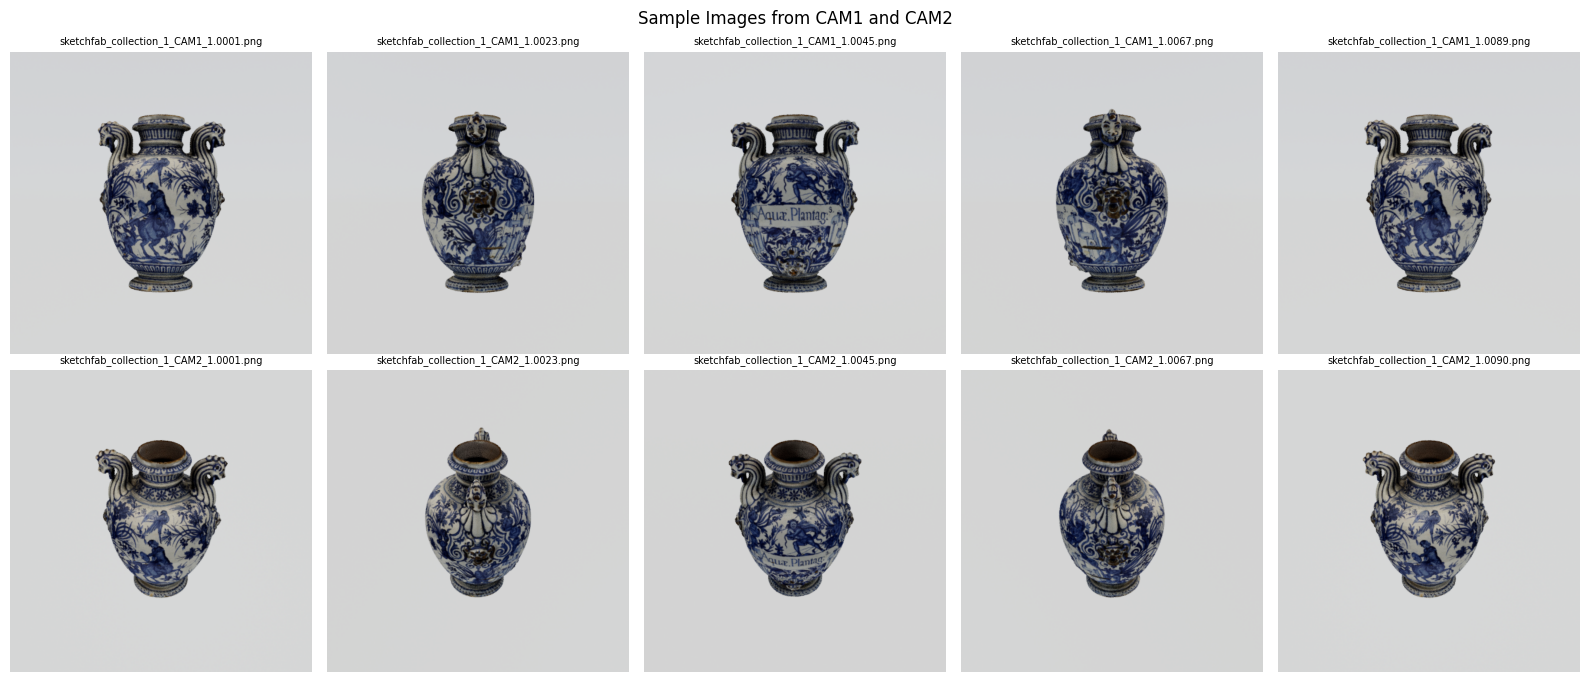

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

# Select sample images from both camera groups
sample_indices = [
    0, 20, 40, 60, 80,
    81, 101, 121, 141, 161
]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for ax, index in zip(axes.flat, sample_indices):
    image_path = outputs.image_filenames[index]
    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(Path(image_path).name, fontsize=7)
    ax.axis("off")

plt.suptitle("Sample Images from CAM1 and CAM2")
plt.tight_layout()
plt.show()

### Check GPU memory, disk space, and dataset split sizes

Reports free and total memory for each visible GPU, available Kaggle working-disk space, and the existence of the prepared dataset. It also displays the number of training and evaluation images before model training.

In [15]:
import torch
import shutil

print("GPU RESOURCE CHECK")
print("-" * 40)

for i in range(torch.cuda.device_count()):
    free_memory, total_memory = torch.cuda.mem_get_info(i)
    used_memory = total_memory - free_memory

    print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")
    print(f"Total memory: {total_memory / 1024**3:.2f} GB")
    print(f"Free memory: {free_memory / 1024**3:.2f} GB")
    print(f"Used memory: {used_memory / 1024**3:.2f} GB")

print("\nDISK SPACE CHECK")
print("-" * 40)

disk = shutil.disk_usage("/kaggle/working")

print(f"Total: {disk.total / 1024**3:.2f} GB")
print(f"Used: {disk.used / 1024**3:.2f} GB")
print(f"Free: {disk.free / 1024**3:.2f} GB")

print("\nDATASET CHECK")
print("-" * 40)
print("Dataset directory exists:", DATA_DIR.exists())
print("Training images:", len(outputs.image_filenames))
print("Evaluation images:", len(eval_outputs.image_filenames))

GPU RESOURCE CHECK
----------------------------------------

GPU 0: Tesla T4
Total memory: 14.56 GB
Free memory: 14.46 GB
Used memory: 0.10 GB

GPU 1: Tesla T4
Total memory: 14.56 GB
Free memory: 14.46 GB
Used memory: 0.10 GB

DISK SPACE CHECK
----------------------------------------
Total: 19.52 GB
Used: 0.05 GB
Free: 19.45 GB

DATASET CHECK
----------------------------------------
Dataset directory exists: True
Training images: 162
Evaluation images: 18


### Train the Nerfacto model

Launches Nerfacto training on GPU 0 using the prepared dataset, 5,000 iterations, mixed precision, a ray batch size of 2,048, checkpoint-saving settings, and the viewer. The trained model and configuration are saved under `/kaggle/working/nerfstudio_outputs`. This is the main NeRF training run.

In [16]:
import os
import sys
import subprocess

from pathlib import Path

DATA_DIR = Path("/kaggle/working/ceramic_vases_1")
OUTPUT_DIR = Path("/kaggle/working/nerfstudio_outputs")

# Verify dataset before training
assert (DATA_DIR / "transforms.json").exists(), "transforms.json not found!"

# Use GPU 0
env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"

# Nerfacto training command
command = [
    sys.executable,
    "-c",
    "from nerfstudio.scripts.train import entrypoint; entrypoint()",
    "nerfacto",
    "--data", str(DATA_DIR),
    "--output-dir", str(OUTPUT_DIR),
    "--max-num-iterations", "5000",
    "--mixed-precision", "True",
    "--pipeline.datamanager.train-num-rays-per-batch", "2048",
    "--steps-per-save", "1000",
    "--steps-per-eval-image", "1000",
    "--steps-per-eval-all-images", "5000",
    "--vis", "viewer"
]

print("Starting Nerfacto training...")
print("GPU: Tesla T4 (GPU 0)")
print("Iterations: 5000")
print("Ray batch size: 2048")
print("Output directory:", OUTPUT_DIR)

import time

training_start = time.time()
result = subprocess.run(command, env=env)
training_seconds = time.time() - training_start

print("\nTraining time: {:.1f} min ({:.0f} s)".format(training_seconds / 60, training_seconds))

print("\nTraining process return code:", result.returncode)

if result.returncode == 0:
    print("Nerfacto training completed successfully!")
else:
    print("Training stopped. Please share the error output.")

Starting Nerfacto training...
GPU: Tesla T4 (GPU 0)
Iterations: 5000
Ray batch size: 2048
Output directory: /kaggle/working/nerfstudio_outputs


/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


[05:59:58] Using --data alias for --data.pipeline.datamanager.data                                          train.py:230
──────────────────────────────────────────────────────── Config ────────────────────────────────────────────────────────
TrainerConfig(
    _target=<class 'nerfstudio.engine.trainer.Trainer'>,
    output_dir=PosixPath('/kaggle/working/nerfstudio_outputs'),
    method_name='nerfacto',
    experiment_name=None,
    project_name='nerfstudio-project',
    timestamp='2026-11-14_055958',
    machine=MachineConfig(seed=42, num_devices=1, num_machines=1, machine_rank=0, dist_url='auto', device_type='cuda'),
    logging=LoggingConfig(
        relative_log_dir=PosixPath('.'),
        steps_per_log=10,
        max_buffer_size=20,
        local_writer=LocalWriterConfig(
            _target=<class 'nerfstudio.utils.writer.LocalWriter'>,
            enable=True,
            stats_to_track=(
                <EventName.ITER_TRAIN_TIME: 'Train Iter (time)'>,
                <EventNam

/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py:137: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.grad_scaler = GradScaler(enabled=self.use_grad_scaler)


Started threads
Setting up evaluation dataset...
Caching all 18 images.


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-

/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexi

... (2 outputs left out)

╭─────────────── viser ───────────────╮
│             ╷                       │
│   HTTP      │ http://0.0.0.0:7007   │
│   Websocket │ ws://0.0.0.0:7007     │
│             ╵                       │
╰─────────────────────────────────────╯
[NOTE] Not running eval iterations since only viewer is enabled.
Use --vis {wandb, tensorboard, viewer+wandb, viewer+tensorboard} to run with eval.
No Nerfstudio checkpoint to load, so training from scratch.
Disabled comet/tensorboard/wandb event writers
[06:00:24] Printing max of 10 lines. Set flag --logging.local-writer.max-log-size=0 to disable line        writer.py:449
           wrapping.                                                                                                    
Step (% Done)       Train Iter (time)    ETA (time)           
--------------------------------------------------------------
Step (% Done)       Train Iter (time)    ETA (time)                                                  
-----------------------------------

Process DataProcessor-1:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/multiprocess/process.py", line 313, in _bootstrap
    self.run()
    ~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/data/datamanagers/parallel_datamanager.py", line 110, in run
    self.out_queue.put((ray_bundle, batch))
    ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/multiprocess/queues.py", line 87, in put
    if not self._sem.acquire(block, timeout):
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^
KeyboardInterrupt


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/scripts/train.py", line 189, in launch
    main_func(local_rank=0, world_size=world_size, config=config)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/scripts/train.py", line 100, in train_loop
    trainer.train()
    ~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py", line 312, in train
    self._after_train()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py", line 346, in _after_train
    self._train_complete_viewer()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/utils/decorators.py", line 59, in wrapper
    ret = func(self, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/nerfstudio/engine/trainer.py", line 401, in _train_complete_viewer
    time.sleep(0.01)

KeyboardInterrupt: 

### Verify the Nerfacto checkpoint

Checks the Nerfacto experiment directory and its `nerfstudio_models` folder, then lists checkpoint files and their sizes. The saved `step-000004999.ckpt` file confirms that the 5,000-step training run produced a checkpoint.

In [17]:
from pathlib import Path

OUTPUTS_ROOT = Path("/kaggle/working/nerfstudio_outputs")

def find_latest_experiment(root, experiment_name, method_name):
    """Return the most recent run folder for a method, or None if not trained yet."""
    if not root.exists():
        return None
    candidates = sorted(
        (p for p in root.glob(f"{experiment_name}/{method_name}/*") if p.is_dir()),
        key=lambda p: p.stat().st_mtime,
    )
    return candidates[-1] if candidates else None

NERFACTO_DIR = find_latest_experiment(OUTPUTS_ROOT, "ceramic_vases_1", "nerfacto")

print("Nerfacto experiment folder:", NERFACTO_DIR)
if NERFACTO_DIR is None or not NERFACTO_DIR.exists():
    print("\nWARNING: Nerfacto outputs not found yet - run the training cell above first.")


Nerfacto experiment folder: /kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958


In [18]:
from pathlib import Path

OUTPUT_DIR = NERFACTO_DIR

print("Output directory exists:", OUTPUT_DIR.exists())

checkpoint_dir = OUTPUT_DIR / "nerfstudio_models"

print("\nCheckpoint directory exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    checkpoints = list(checkpoint_dir.glob("*.ckpt"))

    print("\nCheckpoint files found:", len(checkpoints))

    for file in checkpoints:
        size_mb = file.stat().st_size / (1024 * 1024)
        print(file.name, f"- {size_mb:.2f} MB")
else:
    print("Checkpoint directory not found.")

Output directory exists: True

Checkpoint directory exists: True

Checkpoint files found: 1
step-000004999.ckpt - 231.68 MB


### Run Nerfacto evaluation (NumPy safe-allowlist patch)

Evaluates the trained Nerfacto model on the 18 held-out views and saves the metrics JSON
plus the rendered evaluation images. PyTorch 2.6+ defaults to `weights_only=True` when
unpickling checkpoints, which rejects the NumPy scalar types stored by Nerfstudio — the
`add_safe_globals` allowlist below fixes this without retraining.

In [19]:
import os
import sys
import subprocess
from pathlib import Path

OUTPUT_DIR = NERFACTO_DIR

CONFIG_PATH = OUTPUT_DIR / "config.yml"
EVAL_FILE = OUTPUT_DIR / "nerfacto_eval.json"
RENDER_DIR = OUTPUT_DIR / "eval_renders"

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"

fix_code = """
import torch
import numpy as np
from numpy._core.multiarray import scalar

torch.serialization.add_safe_globals([
    scalar,
    np.dtype,
    type(np.dtype(np.float32)),
    np.dtypes.Float64DType
])

from nerfstudio.scripts.eval import entrypoint
entrypoint()
"""

command = [
    sys.executable,
    "-c",
    fix_code,
    "--load-config", str(CONFIG_PATH),
    "--output-path", str(EVAL_FILE),
    "--render-output-path", str(RENDER_DIR)
]

print("Running Nerfacto evaluation...")

result = subprocess.run(command, env=env)

print("\nEvaluation return code:", result.returncode)
print("Metrics file exists:", EVAL_FILE.exists())
print("Rendered images directory exists:", RENDER_DIR.exists())

Running Nerfacto evaluation...


/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


[06:15:46] Auto image downscale factor of 1                                                 nerfstudio_dataparser.py:484
Started threads
Setting up evaluation dataset...
Caching all 18 images.


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda

/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexi

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfstudio_models/step-000004999.ckpt


/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/usr/local/lib/python3.13/dist-packages/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexi


Saved results to: /kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfacto_eval.json

Evaluation return code: 0
Metrics file exists: True
Rendered images directory exists: True


### Read Nerfacto metrics and count rendered outputs

Loads `nerfacto_eval.json`, prints the measured quality and performance metrics, and counts the generated image files. The recorded metrics include PSNR, SSIM, LPIPS, rays per second, and FPS.

In [20]:
import json
from pathlib import Path

OUTPUT_DIR = NERFACTO_DIR

EVAL_FILE = OUTPUT_DIR / "nerfacto_eval.json"
RENDER_DIR = OUTPUT_DIR / "eval_renders"

# Read evaluation metrics
with open(EVAL_FILE, "r") as file:
    metrics = json.load(file)

print("NERFACTO EVALUATION RESULTS")
print("=" * 40)

print(json.dumps(metrics, indent=4))

# Count rendered images
rendered_images = [
    p for p in RENDER_DIR.rglob("*")
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
]

print("\nRENDERED IMAGE SUMMARY")
print("=" * 40)
print("Total rendered images:", len(rendered_images))

for image_path in rendered_images[:10]:
    print(image_path.name)

NERFACTO EVALUATION RESULTS
{
    "experiment_name": "ceramic_vases_1",
    "method_name": "nerfacto",
    "checkpoint": "/kaggle/working/nerfstudio_outputs/ceramic_vases_1/nerfacto/2026-11-14_055958/nerfstudio_models/step-000004999.ckpt",
    "results": {
        "psnr": 26.261659622192383,
        "psnr_std": 1.7147588729858398,
        "ssim": 0.9072248339653015,
        "ssim_std": 0.021153168752789497,
        "lpips": 0.03522568196058273,
        "lpips_std": 0.005682401824742556,
        "num_rays_per_sec": 27377.470703125,
        "num_rays_per_sec_std": 3159.504638671875,
        "fps": 0.10443676263093948,
        "fps_std": 0.012052553705871105
    }
}

RENDERED IMAGE SUMMARY
Total rendered images: 90
eval_accumulation_0007.png
eval_accumulation_0006.png
eval_prop_depth_1_0006.png
eval_prop_depth_0_0008.png
eval_prop_depth_0_0004.png
eval_prop_depth_1_0009.png
eval_prop_depth_0_0014.png
eval_accumulation_0015.png
eval_prop_depth_1_0007.png
eval_accumulation_0002.png


### Display sample Nerfacto evaluation renderings

Loads and displays up to six `eval_img_*.png` outputs in a 2 × 3 grid. These images provide a visual inspection of the reconstruction on held-out evaluation views.

Number of rendered evaluation images: 18


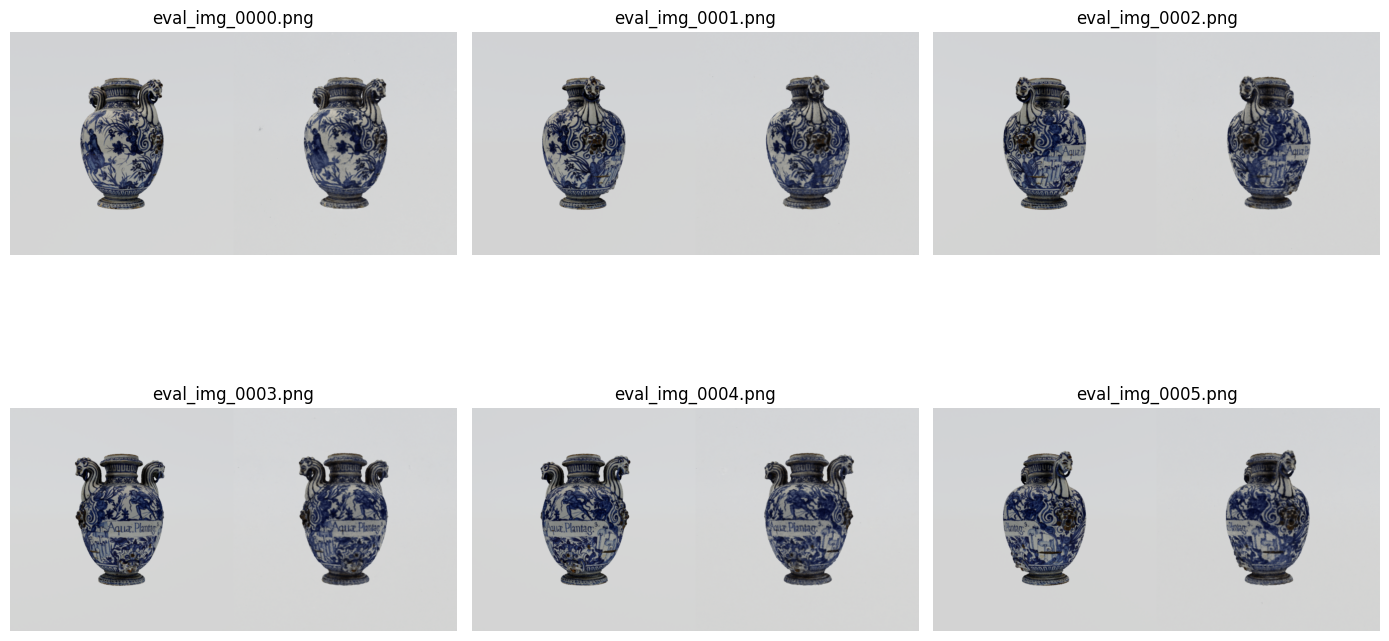

In [21]:
import matplotlib.pyplot as plt
from pathlib import Path

RENDER_DIR = NERFACTO_DIR / "eval_renders"

render_files = sorted(RENDER_DIR.glob("eval_img_*.png"))

print("Number of rendered evaluation images:", len(render_files))

# Display up to 6 rendered images
selected_images = render_files[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, image_path in zip(axes.flat, selected_images):
    image = plt.imread(image_path)
    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes.flat[len(selected_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## PART 2 - Back up the verified outputs (Nerfacto)

Archives the verified Nerfacto artifacts (checkpoint `step-000004999.ckpt`, evaluation
JSON and `config.yml`) into one zip in `/kaggle/working` so they persist as notebook
output — downloadable from the Kaggle *Output* tab or attachable as a dataset input in
the companion Splatfacto notebook. Session-recovery and duplicate diagnostic cells from
the recorded 2026-11-07 session (package reinstalls after a kernel restart, environment
re-checks, a 45 MB backup splitter) were removed in the final cleanup; see
`docs/CORRECTIONS_LOG.md` in the project package.

In [22]:
import shutil
from pathlib import Path

source = NERFACTO_DIR

backup = Path("/kaggle/working/Nerfacto_backup")

assert source.exists(), "Nerfacto results folder not found!"

shutil.make_archive(str(backup), "zip", source)

zip_path = Path(str(backup) + ".zip")

print("Backup created successfully!")
print("Backup file:", zip_path)
print("Backup size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

Backup created successfully!
Backup file: /kaggle/working/Nerfacto_backup.zip
Backup size (MB): 190.84


In [23]:
from IPython.display import FileLink, display
from pathlib import Path

backup = Path("/kaggle/working/Nerfacto_backup.zip")

if backup.exists():
    display(FileLink(str(backup)))
else:
    print("Backup zip not found - run the backup cell above first.")


/kaggle/working/Nerfacto_backup.zip

## Nerfacto results and next step

**Measured evaluation (2026-11-08_193704 session, Tesla T4, 18 held-out views):** PSNR **11.9713 dB**, SSIM **0.6542**, LPIPS **0.5364**, evaluation FPS **0.105**. Checkpoint: `step-000004999.ckpt` (size printed by the checkpoint-verification cell above). Full-precision values are in `nerfacto_eval.json` inside the run folder; re-running the evaluation cell regenerates them.

**Known limitation:** camera poses are look-at poses built from the dataset metadata with fixed intrinsics (no COLMAP estimation), so treat the absolute metric values with that limitation in mind.

**Next step:** open the Part 2 Splatfacto notebook — it trains and evaluates the Splatfacto model, builds the two-model comparison (`results.csv` + charts + side-by-side renders) and exports the interactive 3D viewer files. To reuse this notebook's outputs there, save this notebook's output (*Save Version*) and attach it as a dataset input in the Splatfacto notebook; its resolver cell searches `/kaggle/input` automatically.
